# Fault detection across four sensors

DSE 3170 PBL 3, Section B. Rishabh Srivastava, Mitul Seth and Madhav Mittal.

This extension identifies cold-deck/hot-deck temperature and pressure sensor biases in one simulated dual-duct AHU. The fifth outcome is healthy operation. The earlier outdoor-air benchmark remains separate. Each new native scenario contains one fault; simultaneous faults are untested.

Source: [LBNL dual-duct AHU](https://faultdetection.lbl.gov/dataset/simulated-dd-ahu-dataset/). Collection DOI 10.25984/1881324. Fault definitions: Scientific Data 10, 342 (2023), DOI 10.1038/s41597-023-02197-w, Table 4.

The reserved test is already inspected. This notebook reads saved results and performs fresh inference, without retuning thresholds.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import torch
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
R = ROOT / "results/multisensor_v2"
torch.set_num_threads(4)
summary = json.loads((R / "test_summary.json").read_text())
evidence = json.loads((R / "evidence_summary.json").read_text())
frozen = json.loads((R / "frozen_model.json").read_text())
print("Primary:", summary["primary_family"], "seed", summary["seed"])
print("Classes:", *summary["classes"], sep="\n")

Primary: all_inputs seed 42
Classes:
Healthy
Cold-deck temperature sensor
Hot-deck temperature sensor
Cold-deck pressure sensor
Hot-deck pressure sensor


## Source audit and calendar separation

We selected one healthy file and sixteen native sensor-bias files from a 56-CSV archive. Each file represents the same modeled unit under a different condition. Matching ISO calendar weeks stay in the same partition across every scenario: modulo six equal to zero tests, five validates, and all other values train. Thirty one-minute readings must remain operating, contiguous and in one source day. Temperatures use Fahrenheit. Pressure filename severity tokens differ from the paper, so verified numerical pressure severities are not claimed.

An earlier single-duct source was rejected because outdoor-bias tables were identical and the documented supply-bias filenames were missing. The audit remains in the repository.

In [2]:
counts = pd.read_csv(ROOT / "results/multisensor_v1/cohort_counts.csv")
print(counts.groupby("partition").endpoints.sum().to_string())
print("Hourly training windows:", evidence["sampled_train_windows"])
print("Quarter-hour checkpoint validation windows:", evidence["checkpoint_validation_windows"])
print("All-minute policy validation and test endpoints are retained.")

partition
test           463058
train         2096259
validation     463842
Hourly training windows: 36404
Quarter-hour checkpoint validation windows: 30877
All-minute policy validation and test endpoints are retained.


## Input measurements and five-input comparison

The wider model uses 21 measurements and five commands. Cleaning/scaling fit only healthy active training rows, causal filling resets at day/gap boundaries, and labels/filenames never enter the model. A training-only tree selector uses whole-day grouped permutation on internal held-out training weeks. The five candidates comprise four measurements and one command. Rankings remain conditional on the selector and correlated inputs.

In [3]:
ranking = pd.read_csv(ROOT / "results/multisensor_v1/training_feature_ranking.csv")
print(ranking.head(5).to_string(index=False))
from dccad.multisensor import SensorClassifier
checkpoint = torch.load(R / summary["primary_family"] / "model.pt", map_location="cpu", weights_only=True)
model = SensorClassifier(len(checkpoint["features"]), len(checkpoint["classes"]))
model.load_state_dict(checkpoint["state_dict"])
model.eval()
print(model)
print("Parameters:", sum(p.numel() for p in model.parameters()))

    feature  importance_mean  importance_sd
    HSF_SPD         0.186691       0.010842
    HSF_WAT         0.143574       0.006742
    CSF_SPD         0.119418       0.003572
CHWC_VLV_DM         0.104215       0.007549
    CSF_WAT         0.074511       0.002723
SensorClassifier(
  (encoder): LSTM(26, 32, batch_first=True)
  (head): Sequential(
    (0): Linear(in_features=32, out_features=16, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=16, out_features=5, bias=True)
  )
)
Parameters: 8293


## Reserved test results

Version 1 tested two input sets for up to 20 epochs. Before test inference, Version 2 recorded a longer training budget and increased healthy-class loss weight. Four unique LSTMs and one fixed seed were used. Final selection compared 126 validation policies per candidate, or 504 policies, then froze the primary model and thresholds. The full-input Version 2 model won on validation.

Healthy FPR is FP divided by all healthy minutes. Correct-sensor recall requires the matching faulty sensor label. Any-fault recall only requires raising some fault alarm.

In [4]:
m = summary["primary_test"]
print(pd.DataFrame(m["per_class"])[["sensor", "support", "precision", "recall", "f1"]].to_string(index=False))
print("Accuracy:", "{:.2%}".format(m["accuracy"]))
print("Macro F1:", "{:.2%}".format(m["macro_f1"]))
print("Healthy FPR:", "{:.2%}".format(m["healthy_fpr"]), "from", m["healthy_false_readings"], "/", m["healthy_readings"])
assert not summary["test_used_for_selection"]
print("The 1% FPR target is unmet:", not summary["test_targets_met"])

                      sensor  support  precision   recall       f1
                     Healthy    27640   0.472161 0.979016 0.637073
Cold-deck temperature sensor   103738   0.994304 0.910313 0.950456
 Hot-deck temperature sensor   110560   0.991272 0.875217 0.929636
   Cold-deck pressure sensor   110560   0.992103 0.956766 0.974114
    Hot-deck pressure sensor   110560   0.995016 0.958783 0.976563
Accuracy: 92.87%
Macro F1: 89.36%
Healthy FPR: 2.10% from 580 / 27640
The 1% FPR target is unmet: True


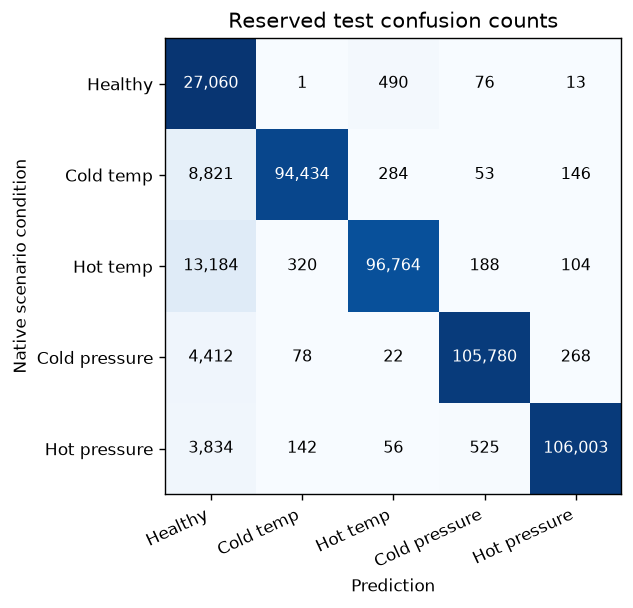

In [5]:
import matplotlib.pyplot as plt
matrix = np.asarray(m["confusion_matrix"])
fig, ax = plt.subplots(figsize=(7, 5))
ax.imshow(matrix / matrix.sum(axis=1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{matrix[i,j]:,}", ha="center", va="center", color="white" if i==j else "black", fontsize=9)
names = ["Healthy", "Cold temp", "Hot temp", "Cold pressure", "Hot pressure"]
ax.set_xticks(range(5), names, rotation=25, ha="right")
ax.set_yticks(range(5), names)
ax.set(xlabel="Prediction", ylabel="Native scenario condition", title="Reserved test confusion counts")
fig.tight_layout()

In [6]:
comparison = pd.read_csv(R / "model_comparison.csv")
print(comparison[["model", "inputs", "accuracy", "macro_f1", "healthy_fpr", "selected_before_test"]].to_string(index=False))
print("Majority five-class baseline:", "{:.2%}".format(evidence["five_class_majority_baseline_accuracy"]))
print("Experimental fault prevalence:", "{:.2%}".format(evidence["test_fault_prevalence"]))

         model  inputs  accuracy  macro_f1  healthy_fpr  selected_before_test
 v1_all_inputs      26  0.778395  0.752239     0.022540                 False
v1_top5_inputs       5  0.632189  0.548816     0.326918                 False
    all_inputs      26  0.928698  0.893569     0.020984                  True
   top5_inputs       5  0.642686  0.564176     0.379920                 False
Majority five-class baseline: 23.88%
Experimental fault prevalence: 94.03%


## Fresh CSV inference

The saved primary uses an immediate alarm policy. Each faulty sensor has its own validation threshold. If multiple sensors pass, the larger class score wins. Softmax scores remain uncalibrated. Reference labels do not affect the scorer.

In [7]:
from dccad.multisensor import score_window
folder = R / summary["primary_family"]
window = pd.read_csv(folder / "example_class_2.csv")
scores = score_window(folder, window)
expected = json.loads((folder / "fresh_window_checks.json").read_text())[2]["scores"]
np.testing.assert_allclose(list(scores.values()), list(expected.values()), rtol=2e-5, atol=2e-6)
window["fault_label"] = "incorrect metadata"
assert score_window(folder, window) == scores
print(pd.Series(scores, name="Uncalibrated class score").to_string())
print("Frozen thresholds:", frozen["policy"]["thresholds"])

Healthy                         0.004269
Cold-deck temperature sensor    0.000309
Hot-deck temperature sensor     0.995388
Cold-deck pressure sensor       0.000032
Hot-deck pressure sensor        0.000002
Frozen thresholds: [0.9282339811325073, 0.9823973774909973, 0.585455060005188, 0.9081256985664368]


## Reproducibility and limitations

The source archive downloads separately for retraining. Saved models, replay data and examples run offline. Start Dashboard.bat opens the four-sensor extension; the sidebar preserves the earlier outdoor-air experiment.

The 2.10% test healthy FPR exceeds the original 1% goal. There are 52 false bursts across 40 active healthy calendar days. Five selected raw inputs perform worse. One simulated unit, overlapping minutes, known bias severities and one fixed seed limit generalization. No field validation, simultaneous-fault coverage or future-failure prediction is established. Do not retune on the already-inspected test and call it a fresh result.

In [8]:
checks = json.loads((R / "verification.json").read_text())
assert checks["status"] == "passed"
print("Complete score arrays reproduced:", checks["complete_score_arrays"])
print("Validation policies reproduced:", checks["validation_policies_reproduced"])
print("Fresh CSV checks:", checks["fresh_csv_and_label_exclusion_checks"])
print("Next evaluation requires new independent reserved data.")

Complete score arrays reproduced: 8
Validation policies reproduced: 504
Fresh CSV checks: 20
Next evaluation requires new independent reserved data.
